# Loan Status Prediction
Predicting loan approval (`Loan_Status`) with a Support Vector Machine.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load and inspect data

In [2]:
loan_dataset = pd.read_csv("loan.csv")
loan_dataset.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Shape:", loan_dataset.shape)
loan_dataset.describe()

Shape: (614, 13)


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [4]:
# Missing values per column
loan_dataset.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

## 3. Clean data

In [5]:
# Drop rows with missing values (614 -> 480 rows) and work on an independent copy
loan_dataset = loan_dataset.dropna().copy()
print("Missing values left:", loan_dataset.isnull().sum().sum())
print("Shape:", loan_dataset.shape)

Missing values left: 0
Shape: (480, 13)


## 4. Encode categorical columns

In [6]:
# Dependents: '3+' -> 3, then convert the whole column to integers
# (the original column mixed strings and integers)
loan_dataset["Dependents"] = loan_dataset["Dependents"].replace("3+", "3").astype(int)

# Explicit mappings; Loan_Status: Y (approved) = 1, N (not approved) = 0
mappings = {
    "Gender": {"Female": 0, "Male": 1},
    "Married": {"No": 0, "Yes": 1},
    "Education": {"Not Graduate": 0, "Graduate": 1},
    "Self_Employed": {"No": 0, "Yes": 1},
    "Property_Area": {"Rural": 0, "Semiurban": 1, "Urban": 2},
    "Loan_Status": {"N": 0, "Y": 1},
}
for col, mapping in mappings.items():
    loan_dataset[col] = loan_dataset[col].map(mapping).astype(int)

loan_dataset.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0,0
2,LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,2,1
3,LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,2,1
4,LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,2,1
5,LP001011,1,1,2,1,1,5417,4196.0,267.0,360.0,1.0,2,1


## 5. Exploratory analysis

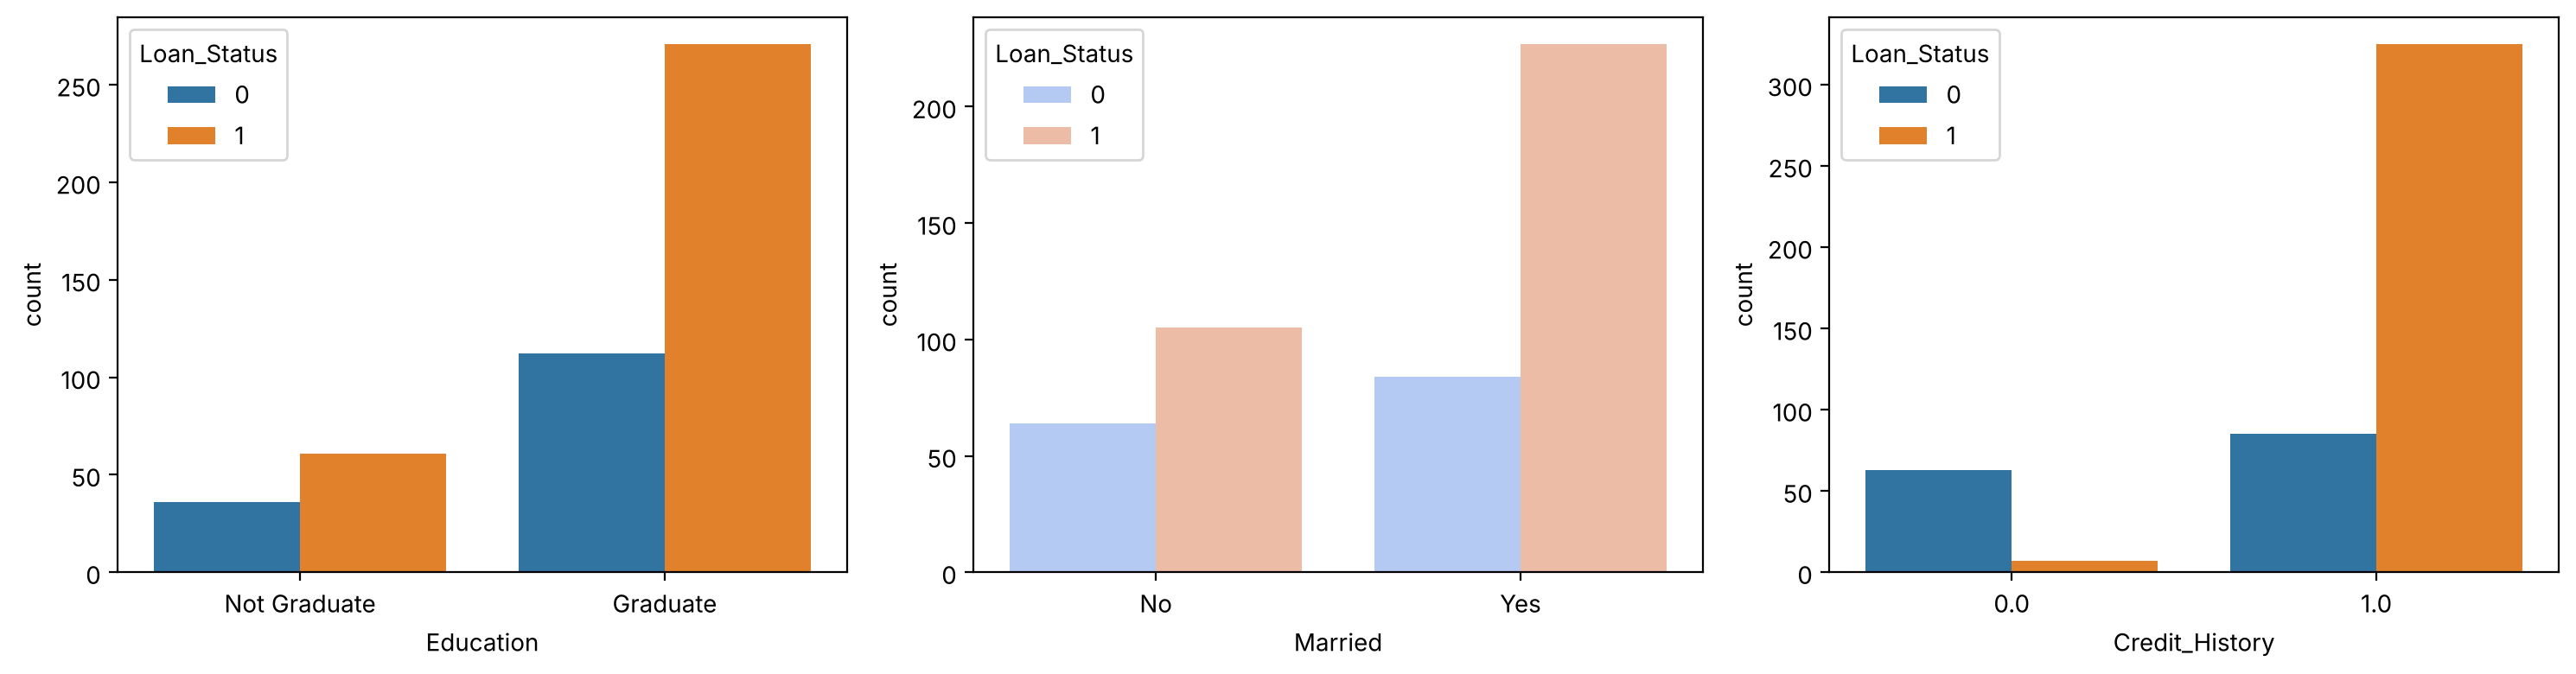

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="Education", hue="Loan_Status", data=loan_dataset, ax=axes[0])
axes[0].set_xticks([0, 1], ["Not Graduate", "Graduate"])
sns.countplot(x="Married", hue="Loan_Status", data=loan_dataset, palette="coolwarm", ax=axes[1])
axes[1].set_xticks([0, 1], ["No", "Yes"])
sns.countplot(x="Credit_History", hue="Loan_Status", data=loan_dataset, ax=axes[2])
plt.tight_layout()
plt.show()

## 6. Features, label and train/test split

In [8]:
X = loan_dataset.drop(columns=["Loan_ID", "Loan_Status"])
y = loan_dataset["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, stratify=y, random_state=42
)
print(X.shape, X_train.shape, X_test.shape)

(480, 11) (432, 11) (48, 11)


## 7. Train the model
A linear SVM is sensitive to feature scale (incomes are in the thousands, binary columns are 0/1), so the features are standardised inside a pipeline. The scaler is fitted on training data only.

In [9]:
classifier = make_pipeline(StandardScaler(), svm.SVC(kernel="linear"))
classifier.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Gender','Married','Dependents',...,'Loan_Amount_Term','Credit_History', 'Property_Area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 8. Evaluate

In [10]:
train_accuracy = accuracy_score(y_train, classifier.predict(X_train))
test_pred = classifier.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred)

print(f"Accuracy on training data: {train_accuracy:.4f}")
print(f"Accuracy on testing data:  {test_accuracy:.4f}")

Accuracy on training data: 0.8102
Accuracy on testing data:  0.7917


              precision    recall  f1-score   support

Not Approved       0.86      0.40      0.55        15
    Approved       0.78      0.97      0.86        33

    accuracy                           0.79        48
   macro avg       0.82      0.68      0.71        48
weighted avg       0.80      0.79      0.77        48



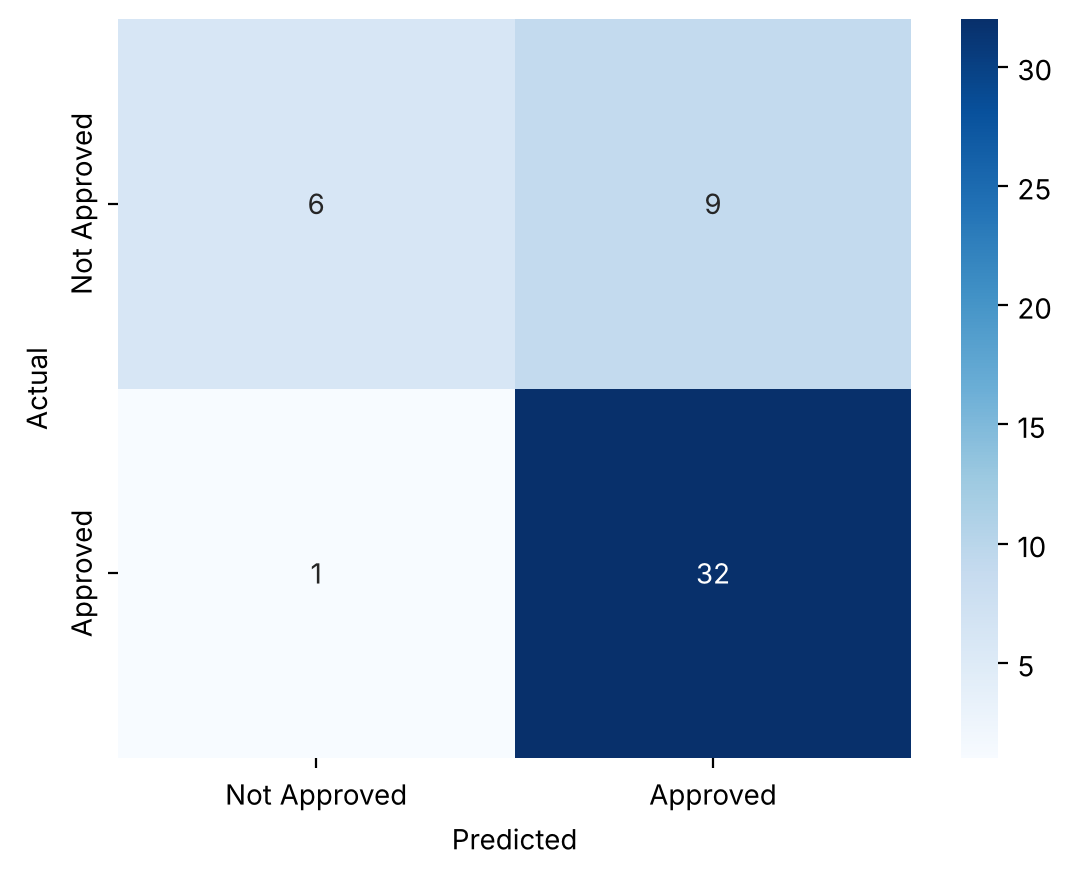

In [11]:
print(classification_report(y_test, test_pred, target_names=["Not Approved", "Approved"]))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Approved", "Approved"], yticklabels=["Not Approved", "Approved"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

## 9. Predictive system
Column order: Gender, Married, Dependents, Education, Self_Employed, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History, Property_Area.

In [12]:
input_data = (1, 1, 1, 1, 0, 4583, 1508, 128, 360, 1, 0)

# Use a DataFrame so the column names match the ones used in training
input_df = pd.DataFrame([input_data], columns=X.columns)
prediction = classifier.predict(input_df)
print("Prediction:", prediction[0])

if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Not Approved")

Prediction: 1
Loan Approved
